In [2]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import functions as F

from config import PARQUET_DIR, get_spark

sns.set_theme(style="whitegrid")
spark = get_spark("eda")

In [3]:
df = spark.read.parquet(str(PARQUET_DIR)).cache()

print("filas:", df.count())
print("itinerarios:", df.select("legId").distinct().count())

filas: 6147142
itinerarios: 518540


In [4]:
df.select(
    F.min("searchDate").alias("busqueda_min"), F.max("searchDate").alias("busqueda_max"),
    F.min("flightDate").alias("vuelo_min"), F.max("flightDate").alias("vuelo_max"),
).show()

df.groupBy("route").count().orderBy(F.desc("count")).show(12)

+------------+------------+----------+----------+
|busqueda_min|busqueda_max| vuelo_min| vuelo_max|
+------------+------------+----------+----------+
|  2022-04-16|  2022-10-05|2022-04-17|2022-11-19|
+------------+------------+----------+----------+

+-------+------+
|  route| count|
+-------+------+
|LAX-BOS|679169|
|BOS-LAX|644390|
|LAX-JFK|625496|
|JFK-LAX|605017|
|LAX-EWR|587270|
|EWR-LAX|544467|
|SFO-BOS|507030|
|BOS-SFO|485993|
|SFO-EWR|400532|
|EWR-SFO|366756|
|JFK-SFO|355357|
|SFO-JFK|345665|
+-------+------+



In [5]:
nulos = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns])
nulos.toPandas().T.rename(columns={0: "nulos"}).query("nulos > 0")

,nulos
totalTravelDistance,240883


In [6]:
print("duplicados (legId, searchDate):",
      df.groupBy("legId", "searchDate").count().filter(F.col("count") > 1).count())

df.groupBy("isAlternateAirport").count().show()

df.select(
    F.min("daysToDeparture").alias("min"), F.max("daysToDeparture").alias("max"),
).show()

duplicados (legId, searchDate): 0
+------------------+-------+
|isAlternateAirport|  count|
+------------------+-------+
|             false|5860516|
|              true| 286626|
+------------------+-------+

+---+---+
|min|max|
+---+---+
|  1| 60|
+---+---+



In [7]:
obs = df.groupBy("legId").count().withColumnRenamed("count", "n_obs").cache()

obs.select(
    F.mean("n_obs").alias("media"),
    F.expr("percentile_approx(n_obs, array(0.25, 0.5, 0.75, 0.95))").alias("p25_p50_p75_p95"),
    F.min("n_obs").alias("min"), F.max("n_obs").alias("max"),
).show(truncate=False)

+------------------+---------------+---+---+
|media             |p25_p50_p75_p95|min|max|
+------------------+---------------+---+---+
|11.854711304817371|[2, 5, 16, 48] |1  |60 |
+------------------+---------------+---+---+



In [8]:
obs = df.groupBy("legId").count().withColumnRenamed("count", "n_obs").cache()

obs.select(
    F.mean("n_obs").alias("media"),
    F.expr("percentile_approx(n_obs, array(0.25, 0.5, 0.75, 0.95))").alias("p25_p50_p75_p95"),
    F.min("n_obs").alias("min"), F.max("n_obs").alias("max"),
).show(truncate=False)

+------------------+---------------+---+---+
|media             |p25_p50_p75_p95|min|max|
+------------------+---------------+---+---+
|11.854711304817371|[2, 5, 16, 48] |1  |60 |
+------------------+---------------+---+---+



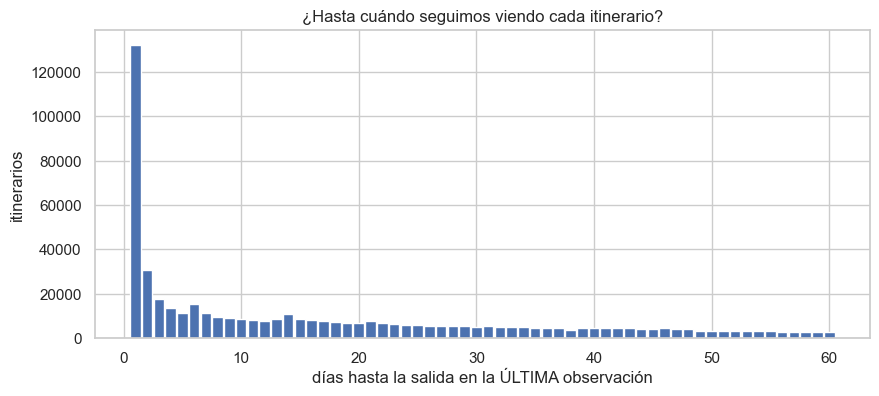

In [9]:
cob = df.groupBy("legId", "flightDate").agg(
    F.min("daysToDeparture").alias("ultima_obs"),
    F.max("daysToDeparture").alias("primera_obs"),
).cache()

cob_pd = cob.groupBy("ultima_obs").count().orderBy("ultima_obs").toPandas()

plt.figure(figsize=(10, 4))
plt.bar(cob_pd["ultima_obs"], cob_pd["count"], width=0.9)
plt.xlabel("días hasta la salida en la ÚLTIMA observación")
plt.ylabel("itinerarios")
plt.title("¿Hasta cuándo seguimos viendo cada itinerario?")
plt.show()

In [10]:
cob.groupBy(F.trunc("flightDate", "month").alias("mes_vuelo")).agg(
    F.count("*").alias("itinerarios"),
    F.round(F.mean("ultima_obs"), 1).alias("media_ultima_obs"),
    F.round(F.mean("primera_obs"), 1).alias("media_primera_obs"),
).orderBy("mes_vuelo").show()

+----------+-----------+----------------+-----------------+
| mes_vuelo|itinerarios|media_ultima_obs|media_primera_obs|
+----------+-----------+----------------+-----------------+
|2022-04-01|      16245|             2.2|              6.0|
|2022-05-01|      64759|             7.8|             20.2|
|2022-06-01|      91162|            16.4|             35.7|
|2022-07-01|      92554|            17.1|             38.3|
|2022-08-01|      88802|            18.3|             42.8|
|2022-09-01|      75996|            16.3|             42.0|
|2022-10-01|      61105|            18.6|             37.7|
|2022-11-01|      27917|            38.7|             46.2|
+----------+-----------+----------------+-----------------+



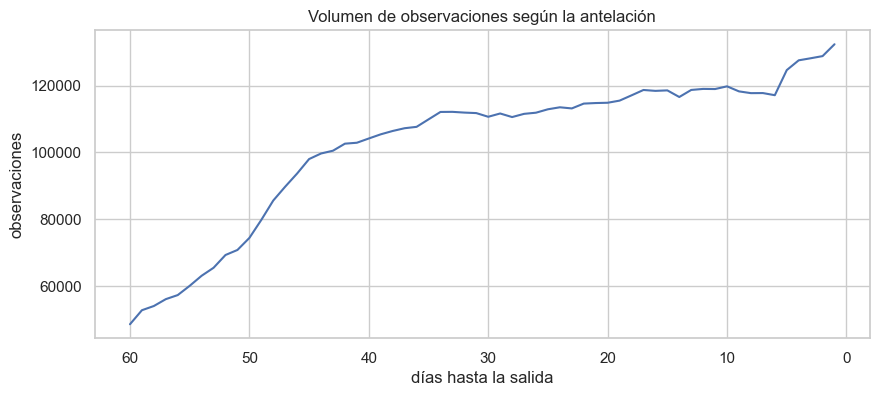

In [12]:
per_dia = df.groupBy("daysToDeparture").count().orderBy("daysToDeparture").toPandas()

plt.figure(figsize=(10, 4))
plt.plot(per_dia["daysToDeparture"], per_dia["count"])
plt.gca().invert_xaxis()
plt.xlabel("días hasta la salida")
plt.ylabel("observaciones")
plt.title("Volumen de observaciones según la antelación")
plt.show()

In [13]:
print("itinerarios con una sola observación:", obs.filter(F.col("n_obs") == 1).count())

df.select("baseFare", "totalFare").summary(
    "count", "mean", "stddev", "min", "25%", "50%", "75%", "max"
).show()

itinerarios con una sola observación: 123572
+-------+------------------+------------------+
|summary|          baseFare|         totalFare|
+-------+------------------+------------------+
|  count|           6147142|           6147142|
|   mean|361.89772718773577|411.17789847607963|
| stddev|203.52960364470843|217.80961487622943|
|    min|               4.0|             49.58|
|    25%|            235.35|             275.6|
|    50%|            332.09|             377.6|
|    75%|            441.86|             497.6|
|    max|           4719.07|            5096.6|
+-------+------------------+------------------+



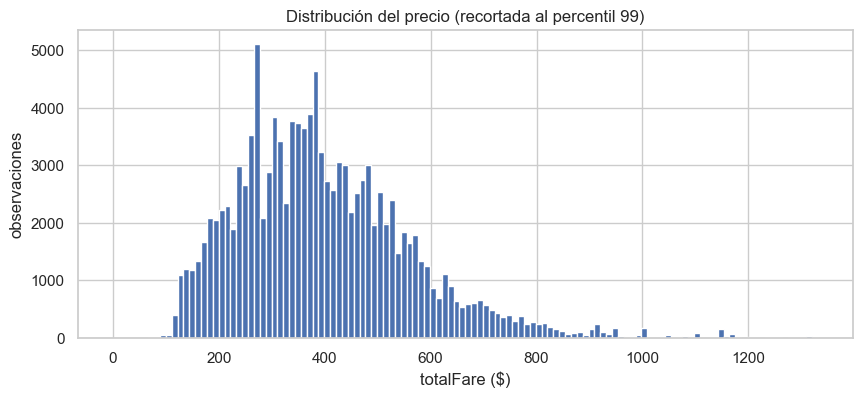

In [14]:
muestra = df.select("totalFare").sample(fraction=0.02, seed=42).toPandas()

plt.figure(figsize=(10, 4))
plt.hist(muestra["totalFare"], bins=120, range=(0, muestra["totalFare"].quantile(0.99)))
plt.xlabel("totalFare ($)")
plt.ylabel("observaciones")
plt.title("Distribución del precio (recortada al percentil 99)")
plt.show()

In [15]:
var = df.groupBy("legId").agg(
    F.count("*").alias("n_obs"),
    F.min("totalFare").alias("fare_min"),
    F.max("totalFare").alias("fare_max"),
).filter(F.col("n_obs") >= 2)

var = var.withColumn("rango_rel", (F.col("fare_max") - F.col("fare_min")) / F.col("fare_min"))

var.select(
    F.round(F.mean("rango_rel"), 3).alias("media"),
    F.expr("percentile_approx(rango_rel, array(0.1, 0.25, 0.5, 0.75, 0.9))").alias("p10_p25_p50_p75_p90"),
).show(truncate=False)

print("itinerarios con precio constante:", var.filter(F.col("rango_rel") == 0).count())

+-----+--------------------------------------------------------------------------------------+
|media|p10_p25_p50_p75_p90                                                                   |
+-----+--------------------------------------------------------------------------------------+
|0.559|[0.0, 0.1059322033898305, 0.34426276534710265, 0.7571064767017689, 1.3515228426395942]|
+-----+--------------------------------------------------------------------------------------+

itinerarios con precio constante: 47673


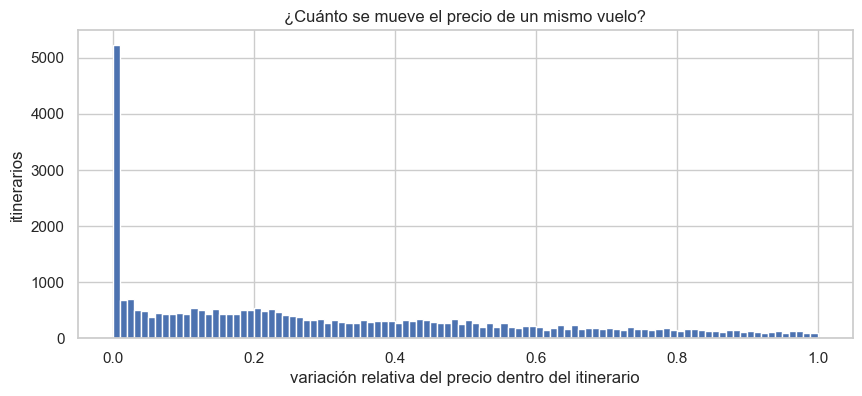

In [16]:
rango_pd = var.sample(fraction=0.1, seed=42).select("rango_rel").toPandas()

plt.figure(figsize=(10, 4))
plt.hist(rango_pd["rango_rel"], bins=100, range=(0, 1))
plt.xlabel("variación relativa del precio dentro del itinerario")
plt.ylabel("itinerarios")
plt.title("¿Cuánto se mueve el precio de un mismo vuelo?")
plt.show()

In [17]:
var.groupBy(
    F.when(F.col("n_obs") <= 5, "2-5")
     .when(F.col("n_obs") <= 15, "6-15")
     .otherwise(">15").alias("grupo_obs")
).agg(
    F.count("*").alias("itinerarios"),
    F.round(F.mean("rango_rel"), 3).alias("rango_medio"),
    F.round(F.expr("percentile_approx(rango_rel, 0.5)"), 3).alias("rango_mediano"),
).orderBy("grupo_obs").show()

+---------+-----------+-----------+-------------+
|grupo_obs|itinerarios|rango_medio|rango_mediano|
+---------+-----------+-----------+-------------+
|      2-5|     148856|      0.193|        0.095|
|     6-15|     113710|      0.473|         0.34|
|      >15|     132402|      1.045|        0.819|
+---------+-----------+-----------+-------------+



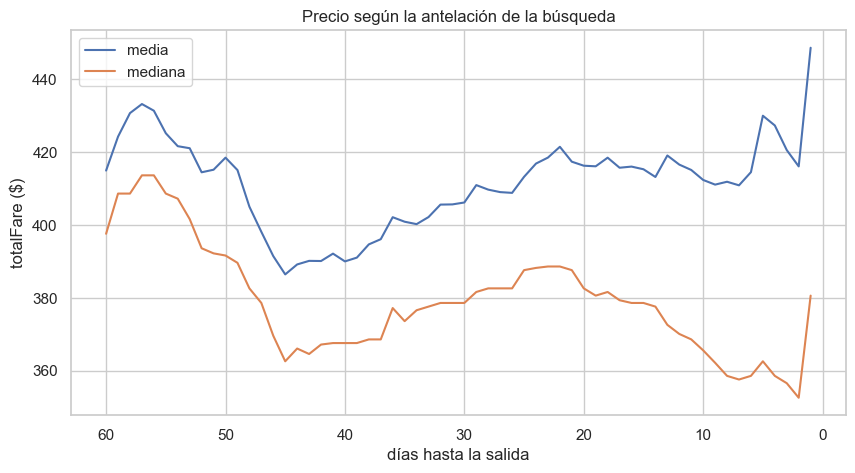

In [18]:
curva = df.groupBy("daysToDeparture").agg(
    F.mean("totalFare").alias("media"),
    F.expr("percentile_approx(totalFare, 0.5)").alias("mediana"),
).orderBy("daysToDeparture").toPandas()

plt.figure(figsize=(10, 5))
plt.plot(curva["daysToDeparture"], curva["media"], label="media")
plt.plot(curva["daysToDeparture"], curva["mediana"], label="mediana")
plt.gca().invert_xaxis()
plt.xlabel("días hasta la salida")
plt.ylabel("totalFare ($)")
plt.title("Precio según la antelación de la búsqueda")
plt.legend()
plt.show()

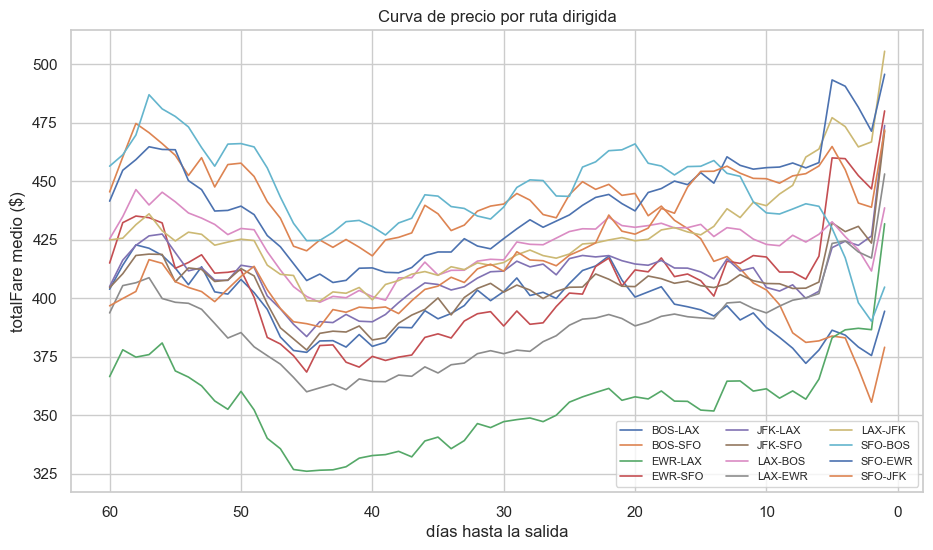

In [19]:
curva_ruta = df.groupBy("route", "daysToDeparture").agg(
    F.mean("totalFare").alias("media")
).toPandas()

plt.figure(figsize=(11, 6))
for ruta, g in curva_ruta.groupby("route"):
    g = g.sort_values("daysToDeparture")
    plt.plot(g["daysToDeparture"], g["media"], lw=1.2, label=ruta)
plt.gca().invert_xaxis()
plt.xlabel("días hasta la salida")
plt.ylabel("totalFare medio ($)")
plt.title("Curva de precio por ruta dirigida")
plt.legend(ncol=3, fontsize=8)
plt.show()

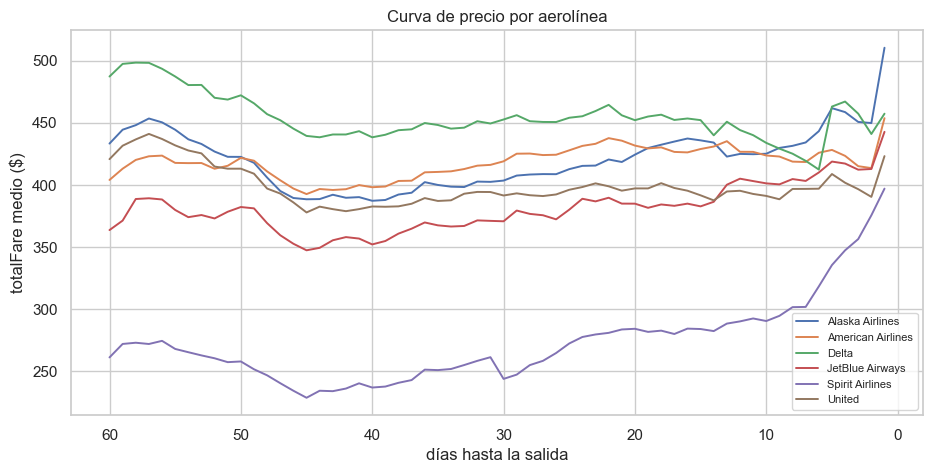

In [20]:
top_aero = [r[0] for r in df.groupBy("firstAirline").count()
            .orderBy(F.desc("count")).limit(6).collect()]

curva_aero = (df.filter(F.col("firstAirline").isin(top_aero))
              .groupBy("firstAirline", "daysToDeparture")
              .agg(F.mean("totalFare").alias("media")).toPandas())

plt.figure(figsize=(11, 5))
for aero, g in curva_aero.groupby("firstAirline"):
    g = g.sort_values("daysToDeparture")
    plt.plot(g["daysToDeparture"], g["media"], lw=1.4, label=aero)
plt.gca().invert_xaxis()
plt.xlabel("días hasta la salida")
plt.ylabel("totalFare medio ($)")
plt.title("Curva de precio por aerolínea")
plt.legend(fontsize=8)
plt.show()

In [21]:
from pyspark.sql import Window

cob.unpersist()
obs.unpersist()

base = df.filter(F.col("flightDate") < "2022-11-01") \
         .withColumn("sd_num", F.datediff("searchDate", F.lit("2022-01-01").cast("date")))

w_fut = Window.partitionBy("legId").orderBy("sd_num").rowsBetween(1, Window.unboundedFollowing)
w_7d = Window.partitionBy("legId").orderBy("sd_num").rangeBetween(1, 7)
w_all = Window.partitionBy("legId")

lab = (base
       .withColumn("min_futuro", F.min("totalFare").over(w_fut))
       .withColumn("min_7d", F.min("totalFare").over(w_7d))
       .withColumn("n_obs", F.count("*").over(w_all))
       .filter(F.col("min_futuro").isNotNull())
       .withColumn("caida_total", (F.col("totalFare") - F.col("min_futuro")) / F.col("totalFare"))
       .withColumn("caida_7d", (F.col("totalFare") - F.col("min_7d")) / F.col("totalFare"))
       .cache())

print("observaciones etiquetables:", lab.count())
print("sin ninguna búsqueda en los 7 días siguientes:", lab.filter(F.col("min_7d").isNull()).count())

observaciones etiquetables: 5481219
sin ninguna búsqueda en los 7 días siguientes: 174437


In [22]:
def prevalencias(col):
    return lab.select(
        F.round(F.mean((F.col(col) > 0).cast("double")) * 100, 2).alias("margen_0"),
        F.round(F.mean((F.col(col) >= 0.03).cast("double")) * 100, 2).alias("margen_3"),
        F.round(F.mean((F.col(col) >= 0.05).cast("double")) * 100, 2).alias("margen_5"),
        F.round(F.mean((F.col(col) >= 0.10).cast("double")) * 100, 2).alias("margen_10"),
    )

print("etiqueta = mínimo futuro hasta la salida (%)")
prevalencias("caida_total").show()

print("etiqueta = mínimo en los próximos 7 días (%)")
prevalencias("caida_7d").show()

etiqueta = mínimo futuro hasta la salida (%)
+--------+--------+--------+---------+
|margen_0|margen_3|margen_5|margen_10|
+--------+--------+--------+---------+
|   65.41|   62.39|   60.41|    54.97|
+--------+--------+--------+---------+

etiqueta = mínimo en los próximos 7 días (%)
+--------+--------+--------+---------+
|margen_0|margen_3|margen_5|margen_10|
+--------+--------+--------+---------+
|   44.95|    40.6|   38.48|    32.93|
+--------+--------+--------+---------+



In [23]:
grupo = (F.when(F.col("n_obs") <= 5, "2-5")
          .when(F.col("n_obs") <= 15, "6-15")
          .otherwise(">15").alias("grupo_obs"))

lab.groupBy(grupo).agg(
    F.count("*").alias("observaciones"),
    F.round(F.mean((F.col("caida_total") >= 0.05).cast("double")) * 100, 2).alias("esperar_total"),
    F.round(F.mean((F.col("caida_7d") >= 0.05).cast("double")) * 100, 2).alias("esperar_7d"),
).orderBy("grupo_obs").show()

+---------+-------------+-------------+----------+
|grupo_obs|observaciones|esperar_total|esperar_7d|
+---------+-------------+-------------+----------+
|      2-5|       296981|        25.87|     17.78|
|     6-15|       905554|        42.32|     27.41|
|      >15|      4278684|        66.63|     41.86|
+---------+-------------+-------------+----------+



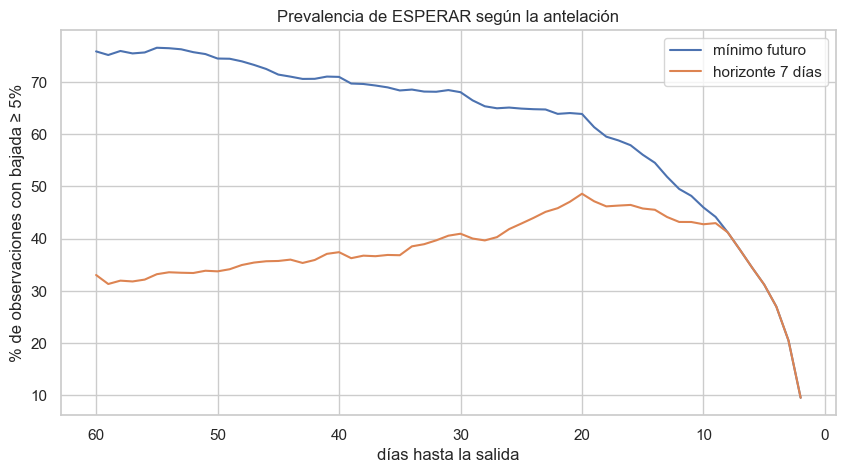

In [24]:
prev_dia = lab.groupBy("daysToDeparture").agg(
    (F.mean((F.col("caida_total") >= 0.05).cast("double")) * 100).alias("total"),
    (F.mean((F.col("caida_7d") >= 0.05).cast("double")) * 100).alias("horizonte_7d"),
).orderBy("daysToDeparture").toPandas()

plt.figure(figsize=(10, 5))
plt.plot(prev_dia["daysToDeparture"], prev_dia["total"], label="mínimo futuro")
plt.plot(prev_dia["daysToDeparture"], prev_dia["horizonte_7d"], label="horizonte 7 días")
plt.gca().invert_xaxis()
plt.xlabel("días hasta la salida")
plt.ylabel("% de observaciones con bajada ≥ 5%")
plt.title("Prevalencia de ESPERAR según la antelación")
plt.legend()
plt.show()

In [25]:
w_cnt = Window.partitionBy("legId").orderBy("sd_num").rangeBetween(1, 7)
lab2 = lab.withColumn("n_7d", F.count("totalFare").over(w_cnt)).cache()

lab2.groupBy(grupo).agg(
    F.round(F.mean("n_7d"), 2).alias("media_obs_en_ventana"),
    F.expr("percentile_approx(n_7d, array(0.25, 0.5, 0.75))").alias("p25_p50_p75"),
).orderBy("grupo_obs").show(truncate=False)

+---------+--------------------+-----------+
|grupo_obs|media_obs_en_ventana|p25_p50_p75|
+---------+--------------------+-----------+
|2-5      |0.68                |[0, 0, 1]  |
|6-15     |2.52                |[1, 2, 4]  |
|>15      |5.18                |[4, 6, 7]  |
+---------+--------------------+-----------+



In [26]:
for minimo in [1, 3, 5, 6]:
    sub = lab2.filter((F.col("n_7d") >= minimo) & (F.col("daysToDeparture") >= 7))
    print(f"--- exigiendo al menos {minimo} observaciones en la ventana ---")
    sub.groupBy(grupo).agg(
        F.count("*").alias("observaciones"),
        F.round(F.mean((F.col("caida_7d") >= 0.05).cast("double")) * 100, 2).alias("esperar_7d"),
    ).orderBy("grupo_obs").show()

--- exigiendo al menos 1 observaciones en la ventana ---
+---------+-------------+----------+
|grupo_obs|observaciones|esperar_7d|
+---------+-------------+----------+
|      2-5|       110326|     20.67|
|     6-15|       654678|     29.34|
|      >15|      3832021|     43.56|
+---------+-------------+----------+

--- exigiendo al menos 3 observaciones en la ventana ---
+---------+-------------+----------+
|grupo_obs|observaciones|esperar_7d|
+---------+-------------+----------+
|      2-5|        10882|     27.47|
|     6-15|       384808|     34.32|
|      >15|      3539627|     45.09|
+---------+-------------+----------+

--- exigiendo al menos 5 observaciones en la ventana ---
+---------+-------------+----------+
|grupo_obs|observaciones|esperar_7d|
+---------+-------------+----------+
|     6-15|       166904|     37.75|
|      >15|      2979050|     46.79|
+---------+-------------+----------+

--- exigiendo al menos 6 observaciones en la ventana ---
+---------+-------------+----

In [27]:
dataset = (lab2
           .filter((F.col("n_7d") >= 5) & (F.col("daysToDeparture") >= 7))
           .withColumn("label", (F.col("caida_7d") >= 0.05).cast("int"))
           .cache())

print("filas:", dataset.count())
print("itinerarios:", dataset.select("legId").distinct().count())

dataset.groupBy("label").count().show()

dataset.select(
    F.min("flightDate").alias("vuelo_min"), F.max("flightDate").alias("vuelo_max"),
    F.min("daysToDeparture").alias("dtd_min"), F.max("daysToDeparture").alias("dtd_max"),
).show()

filas: 3145954
itinerarios: 179278
+-----+-------+
|label|  count|
+-----+-------+
|    0|1689112|
|    1|1456842|
+-----+-------+

+----------+----------+-------+-------+
| vuelo_min| vuelo_max|dtd_min|dtd_max|
+----------+----------+-------+-------+
|2022-04-23|2022-10-31|      7|     60|
+----------+----------+-------+-------+



In [28]:
def prevalencia_por(col, orden=None):
    t = dataset.groupBy(col).agg(
        F.count("*").alias("n"),
        F.round(F.mean("label") * 100, 2).alias("esperar_pct"),
    )
    return t.orderBy(orden if orden else col)

for c in ["isBasicEconomy", "isRefundable", "isNonStop", "isAlternateAirport",
          "firstCabin", "nSegments", "nAirlines"]:
    prevalencia_por(c).show()

+--------------+-------+-----------+
|isBasicEconomy|      n|esperar_pct|
+--------------+-------+-----------+
|         false|2672749|       49.1|
|          true| 473205|      30.53|
+--------------+-------+-----------+

+------------+-------+-----------+
|isRefundable|      n|esperar_pct|
+------------+-------+-----------+
|       false|3145954|      46.31|
+------------+-------+-----------+

+---------+-------+-----------+
|isNonStop|      n|esperar_pct|
+---------+-------+-----------+
|    false|1491174|       43.6|
|     true|1654780|      48.75|
+---------+-------+-----------+

+------------------+-------+-----------+
|isAlternateAirport|      n|esperar_pct|
+------------------+-------+-----------+
|             false|3012457|      46.29|
|              true| 133497|      46.71|
+------------------+-------+-----------+

+-------------+-------+-----------+
|   firstCabin|      n|esperar_pct|
+-------------+-------+-----------+
|     business|   1121|      24.09|
|        coach|31

In [38]:
def prevalencia_por(col, orden=None):
    t = dataset.groupBy(col).agg(
        F.count("*").alias("n"),
        F.round(F.mean("label") * 100, 2).alias("esperar_pct"),
    )
    return t.orderBy(orden) if orden is not None else t.orderBy(col)


prevalencia_por("route", F.desc("esperar_pct")).show(12)

(dataset.groupBy("firstAirline")
 .agg(F.count("*").alias("n"), F.round(F.mean("label") * 100, 2).alias("esperar_pct"))
 .filter(F.col("n") > 20000)
 .orderBy(F.desc("esperar_pct"))
 .show(15))

+-------+------+-----------+
|  route|     n|esperar_pct|
+-------+------+-----------+
|SFO-JFK|211075|      49.23|
|JFK-SFO|220473|      48.13|
|LAX-BOS|317737|      47.84|
|LAX-JFK|344399|      47.79|
|JFK-LAX|351495|      47.12|
|LAX-EWR|300695|      46.74|
|SFO-BOS|237295|      46.52|
|BOS-LAX|295594|      45.71|
|EWR-LAX|280920|      45.37|
|BOS-SFO|216333|      44.28|
|SFO-EWR|191820|      42.45|
|EWR-SFO|178118|      41.47|
+-------+------+-----------+

+--------------------+------+-----------+
|        firstAirline|     n|esperar_pct|
+--------------------+------+-----------+
|     Spirit Airlines| 99163|      59.98|
|     JetBlue Airways|593655|      52.35|
|               Delta|510004|      48.21|
|              United|606261|      44.43|
|   American Airlines|961712|      43.43|
|     Alaska Airlines|318891|      41.36|
|Sun Country Airlines| 54963|      38.44|
+--------------------+------+-----------+



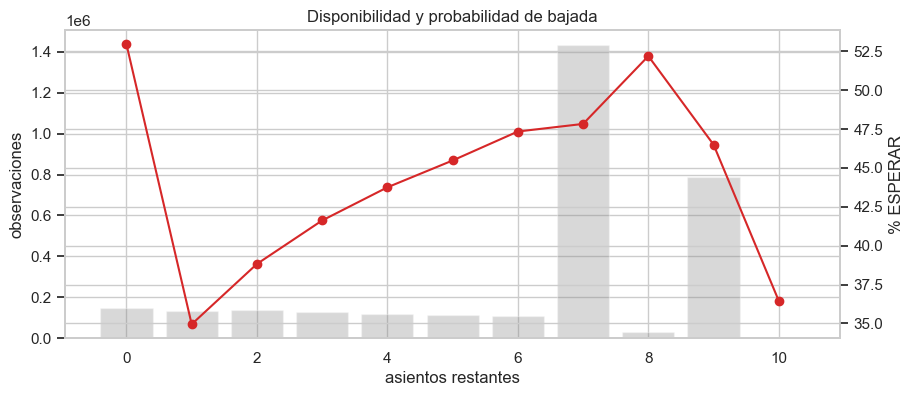

In [31]:
asientos = (dataset.groupBy("seatsRemaining")
            .agg(F.count("*").alias("n"), (F.mean("label") * 100).alias("esperar_pct"))
            .orderBy("seatsRemaining").toPandas())

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(asientos["seatsRemaining"], asientos["n"], alpha=0.3, color="gray")
ax1.set_ylabel("observaciones")
ax2 = ax1.twinx()
ax2.plot(asientos["seatsRemaining"], asientos["esperar_pct"], marker="o", color="tab:red")
ax2.set_ylabel("% ESPERAR")
ax1.set_xlabel("asientos restantes")
plt.title("Disponibilidad y probabilidad de bajada")
plt.show()

In [32]:
w_mercado = Window.partitionBy("route", "flightDate", "searchDate")

rel = (dataset
       .withColumn("precio_mercado", F.mean("totalFare").over(w_mercado))
       .withColumn("precio_rel", F.col("totalFare") / F.col("precio_mercado"))
       .withColumn("tramo", F.floor(F.col("precio_rel") * 5) / 5))

(rel.filter(F.col("tramo").between(0.4, 2.0))
 .groupBy("tramo")
 .agg(F.count("*").alias("n"), F.round(F.mean("label") * 100, 2).alias("esperar_pct"))
 .orderBy("tramo").show(20))

+-----+-------+-----------+
|tramo|      n|esperar_pct|
+-----+-------+-----------+
|  0.4| 136333|      28.43|
|  0.6| 649450|       37.6|
|  0.8|1062718|      44.62|
|  1.0| 717585|      52.49|
|  1.2| 310195|      56.69|
|  1.4| 129319|      56.45|
|  1.6|  61816|      53.89|
|  1.8|  28858|      55.78|
|  2.0|  14615|      58.86|
+-----+-------+-----------+



In [33]:
(dataset
 .withColumn("dow", F.dayofweek("flightDate"))
 .groupBy("dow", F.date_format("flightDate", "E").alias("dia_vuelo"))
 .agg(F.count("*").alias("n"), F.round(F.mean("label") * 100, 2).alias("esperar_pct"))
 .orderBy("dow").show())

(dataset
 .groupBy(F.month("flightDate").alias("mes_vuelo"))
 .agg(F.count("*").alias("n"), F.round(F.mean("label") * 100, 2).alias("esperar_pct"))
 .orderBy("mes_vuelo").show())

+---+---------+------+-----------+
|dow|dia_vuelo|     n|esperar_pct|
+---+---------+------+-----------+
|  1|      Sun|420829|      48.11|
|  2|      Mon|446130|      47.11|
|  3|      Tue|473737|      44.52|
|  4|      Wed|471132|      45.11|
|  5|      Thu|455797|      46.41|
|  6|      Fri|449262|      46.97|
|  7|      Sat|429067|      46.21|
+---+---------+------+-----------+

+---------+------+-----------+
|mes_vuelo|     n|esperar_pct|
+---------+------+-----------+
|        4| 12338|      40.94|
|        5|249555|       41.4|
|        6|397123|       44.4|
|        7|501433|      55.07|
|        8|811176|      51.21|
|        9|749078|      43.18|
|       10|425251|      36.96|
+---------+------+-----------+



In [39]:
w_mercado = Window.partitionBy("route", "flightDate", "searchDate")

dataset = (dataset
           .withColumn("precio_rel", F.col("totalFare") / F.mean("totalFare").over(w_mercado))
           .cache())

print("filas:", dataset.count())
dataset.select("precio_rel").summary("min", "25%", "50%", "75%", "max").show()

filas: 3145954
+-------+------------------+
|summary|        precio_rel|
+-------+------------------+
|    min|0.1890858315458286|
|    25%|0.7991242633352966|
|    50%|0.9468037563804207|
|    75%|1.1240954970958958|
|    max|  8.85550173836166|
+-------+------------------+



In [40]:
w_it = Window.partitionBy("legId").orderBy(F.rand(42))

muestra_sp = (dataset
              .filter(F.col("flightDate") < "2022-09-01")
              .withColumn("rn", F.row_number().over(w_it))
              .filter(F.col("rn") == 1)
              .orderBy(F.rand(42))
              .limit(6000)
              .cache())

print("itinerarios en la muestra:", muestra_sp.count())
muestra_sp.groupBy("label").count().show()

itinerarios en la muestra: 6000
+-----+-----+
|label|count|
+-----+-----+
|    0| 3332|
|    1| 2668|
+-----+-----+



In [41]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import (StringIndexer, OneHotEncoder, VectorAssembler,
                                StandardScaler, PCA as SparkPCA)

cat = ["route", "firstAirline", "firstCabin"]
num = ["daysToDeparture", "totalFare", "precio_rel", "seatsRemaining",
       "durationMinutes", "nSegments", "depHour", "elapsedDays"]

etapas = [
    StringIndexer(inputCols=cat, outputCols=[c + "_idx" for c in cat], handleInvalid="keep"),
    OneHotEncoder(inputCols=[c + "_idx" for c in cat], outputCols=[c + "_ohe" for c in cat]),
    VectorAssembler(inputCols=num + [c + "_ohe" for c in cat],
                    outputCol="features_raw", handleInvalid="skip"),
    StandardScaler(inputCol="features_raw", outputCol="features", withMean=True, withStd=True),
]

prep = Pipeline(stages=etapas).fit(muestra_sp)
proj = prep.transform(muestra_sp)

pca2 = SparkPCA(k=2, inputCol="features", outputCol="pca2").fit(proj)
print("varianza explicada por las 2 componentes:", pca2.explainedVariance.toArray().round(3))

pdf = pca2.transform(proj).select(
    "pca2", "features", "label", "route", "firstAirline", "daysToDeparture", "totalFare"
).toPandas()
print(len(pdf))

varianza explicada por las 2 componentes: [0.085 0.069]
6000


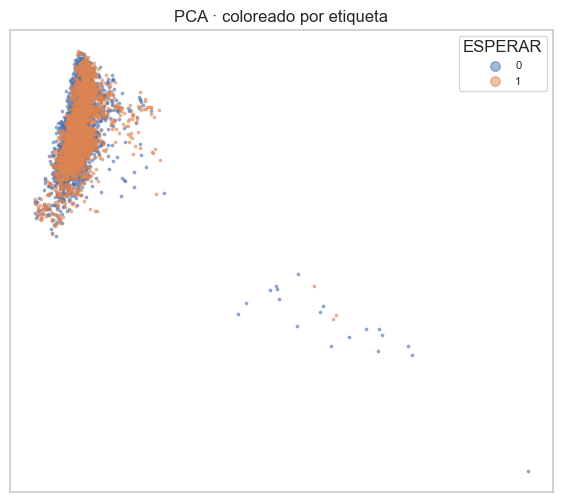

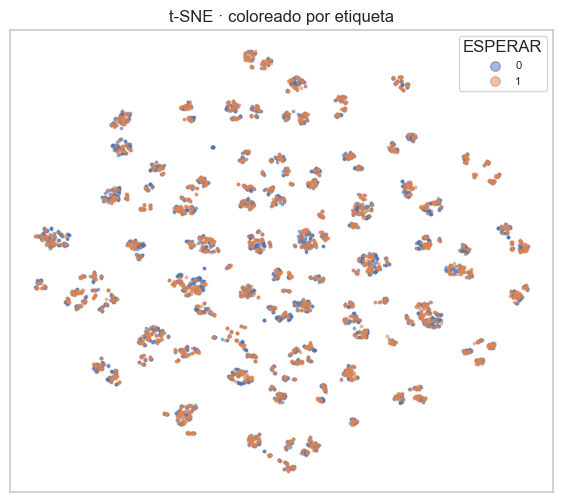

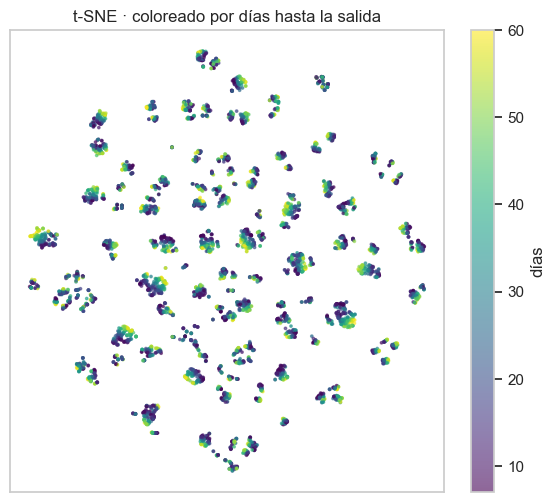

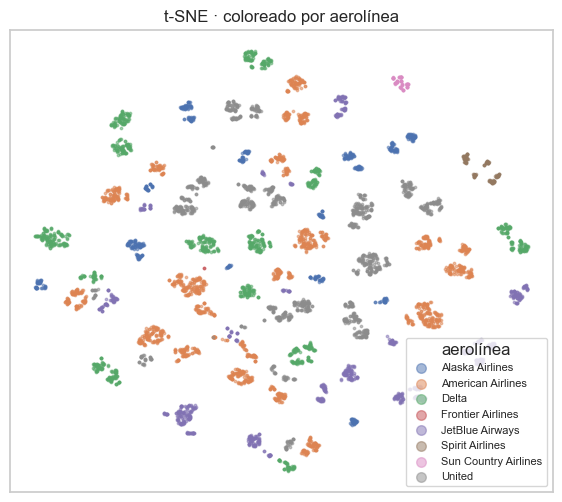

In [42]:
import numpy as np
from sklearn.manifold import TSNE

X = np.vstack(pdf["features"].apply(lambda v: v.toArray()))
emb_pca = np.vstack(pdf["pca2"].apply(lambda v: v.toArray()))
emb_tsne = TSNE(n_components=2, perplexity=30, random_state=42, init="pca").fit_transform(X)


def pintar(emb, titulo, color, etiqueta_color, discreta=True):
    plt.figure(figsize=(7, 6))
    if discreta:
        for v in sorted(pdf[color].unique()):
            m = pdf[color] == v
            plt.scatter(emb[m, 0], emb[m, 1], s=3, alpha=0.5, label=str(v))
        plt.legend(markerscale=4, fontsize=8, title=etiqueta_color)
    else:
        s = plt.scatter(emb[:, 0], emb[:, 1], c=pdf[color], s=3, alpha=0.6, cmap="viridis")
        plt.colorbar(s, label=etiqueta_color)
    plt.title(titulo)
    plt.xticks([]); plt.yticks([])
    plt.show()


pintar(emb_pca, "PCA · coloreado por etiqueta", "label", "ESPERAR")
pintar(emb_tsne, "t-SNE · coloreado por etiqueta", "label", "ESPERAR")
pintar(emb_tsne, "t-SNE · coloreado por días hasta la salida", "daysToDeparture",
       "días", discreta=False)
pintar(emb_tsne, "t-SNE · coloreado por aerolínea", "firstAirline", "aerolínea")

In [45]:
dataset.select(
    F.expr("""
        transform(
            percentile_approx(caida_7d * 100, array(0.05, 0.25, 0.5, 0.75, 0.9, 0.95)),
            x -> round(x, 2)
        )
    """).alias("percentiles_caida_pct")
).show(truncate=False)

dataset.select(
    F.round(F.mean(F.col("totalFare") - F.col("min_7d")), 2).alias("cambio_medio_usd"),
    F.round(F.mean((F.col("caida_7d") > 0).cast("double")) * 100, 2).alias("pct_alguna_bajada"),
).show()

+---------------------------------------+
|percentiles_caida_pct                  |
+---------------------------------------+
|[-10.45, 0.0, 2.05, 17.56, 29.2, 35.86]|
+---------------------------------------+

+----------------+-----------------+
|cambio_medio_usd|pct_alguna_bajada|
+----------------+-----------------+
|           40.05|            52.73|
+----------------+-----------------+



In [44]:
import pandas as pd

filas = []
for m in [0.0, 0.02, 0.03, 0.05, 0.07, 0.10, 0.15]:
    es = F.col("caida_7d") >= m
    ahorro = F.col("totalFare") - F.col("min_7d")
    r = dataset.select(
        F.mean(es.cast("double")).alias("prev"),
        F.mean(F.when(es, ahorro)).alias("ahorro_medio"),
        F.expr(f"percentile_approx(CASE WHEN caida_7d >= {m} THEN totalFare - min_7d END, 0.5)")
         .alias("ahorro_mediano"),
        F.mean(F.when(~es, F.greatest(-ahorro, F.lit(0.0)))).alias("coste_medio"),
    ).first()
    filas.append({
        "margen_%": round(m * 100, 1),
        "prevalencia_%": round(r["prev"] * 100, 2),
        "ahorro_medio_$": round(r["ahorro_medio"], 2),
        "ahorro_mediano_$": round(r["ahorro_mediano"], 2),
        "coste_medio_si_esperas_$": round(r["coste_medio"], 2),
    })

pd.DataFrame(filas)

,margen_%,prevalencia_%,ahorro_medio_$,ahorro_mediano_$,coste_medio_si_esperas_$
0,0.0,91.82,48.33,19.99,52.85
1,2.0,50.06,88.35,65.00,8.65
2,3.0,48.37,91.07,66.00,8.37
3,5.0,46.31,94.43,70.00,8.05
4,7.0,44.30,97.63,70.00,7.76
5,10.0,40.59,103.60,76.00,7.27
6,15.0,30.47,122.72,90.00,6.22
